# Telco Customer Churn Prediction
## Stage 1 & 2: Data Exploration & Initial Auditing

**Dataset:** `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`  
**Target Column:** `Churn` (Binary: 'Yes' / 'No')  

### Scope of Stage 1 & 2:
- Environment and dependency configuration
- Data loading, structural inspection, and integrity checks
- Data type conversion for `TotalCharges` (coercing blank strings without dropping or imputing)
- Target variable distribution analysis
- Exploratory data visualization across key categorical and numerical drivers

## 1. Setup and Library Imports

In [1]:
# Import required core libraries for data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for all plots
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

## 2. Data Loading and Initial Inspection

In [2]:
# Load dataset and print structural information, dtypes, missing values, and duplicates
data_path = 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(data_path)

print("=== Dataset Shape ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("=== First 5 Rows ===")
display(df.head())

print("\n=== Data Types ===")
print(df.dtypes)

print("\n=== Missing Values per Column ===")
print(df.isnull().sum())

print(f"\n=== Duplicate Rows Count ===")
print(f"Duplicate rows: {df.duplicated().sum()}")

=== Dataset Shape ===
Rows: 7043, Columns: 21

=== First 5 Rows ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



=== Data Types ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== Missing Values per Column ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract     

## 3. Data Type Correction: TotalCharges

In [3]:
# Convert TotalCharges to numeric, coercing blank string values to NaN without dropping or filling
# Detect blank string occurrences before conversion
blank_count = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Blank string occurrences in TotalCharges: {blank_count}")

# Convert to numeric format (errors='coerce' replaces unparseable blank strings with NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Audit and report how many values became missing
missing_count = df['TotalCharges'].isnull().sum()
missing_pct = (missing_count / len(df)) * 100

print(f"Missing values in TotalCharges after numeric conversion: {missing_count} ({missing_pct:.2f}%)")
print(f"Updated dtype for TotalCharges: {df['TotalCharges'].dtype}")

Blank string occurrences in TotalCharges: 11
Missing values in TotalCharges after numeric conversion: 11 (0.16%)
Updated dtype for TotalCharges: float64


## 4. Target Variable Analysis (Churn)

In [4]:
# Print target variable (Churn) raw counts and relative percentages
churn_counts = df['Churn'].value_counts()
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_percentages.round(2)
})

print("=== Churn Target Variable Summary ===")
print(churn_summary)

=== Churn Target Variable Summary ===
       Count  Percentage (%)
Churn                       
No      5174           73.46
Yes     1869           26.54


## 5. Exploratory Data Visualizations

### 5.1 Churn Class Balance

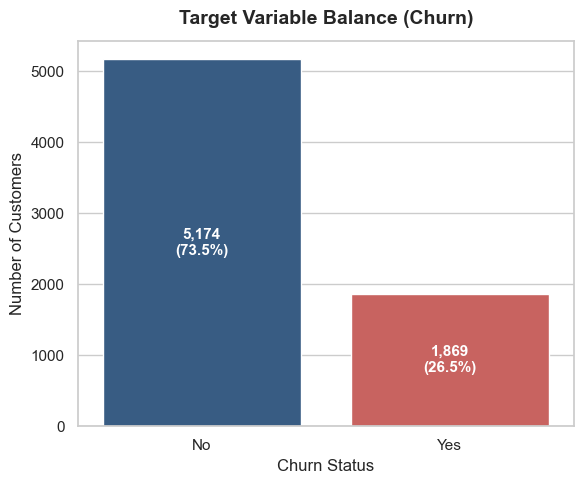

In [5]:
# Plot target variable class balance with frequency and percentage annotations
fig, ax = plt.subplots(figsize=(6, 5))
palette = {'No': '#2b5c8f', 'Yes': '#d9534f'}

sns.countplot(data=df, x='Churn', hue='Churn', palette=palette, legend=False, ax=ax)
ax.set_title('Target Variable Balance (Churn)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Churn Status', fontsize=12)
ax.set_ylabel('Number of Customers', fontsize=12)

# Annotate bars with counts and percentages
total_count = len(df)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total_count) * 100
    ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2 Churn Rate by Contract Type

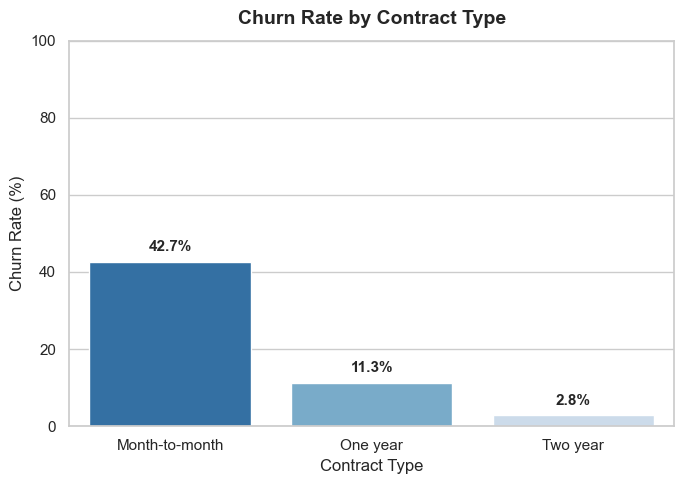

In [6]:
# Calculate and plot customer churn rate across contract types
contract_churn = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index()
contract_churn.columns = ['Contract', 'ChurnRate']

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=contract_churn, x='Contract', y='ChurnRate', hue='Contract', palette='Blues_r', legend=False, ax=ax)
ax.set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Contract Type', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_ylim(0, 100)

for p in ax.patches:
    rate = p.get_height()
    ax.annotate(f"{rate:.1f}%",
                (p.get_x() + p.get_width() / 2., rate + 2),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.3 Churn Rate by Internet Service

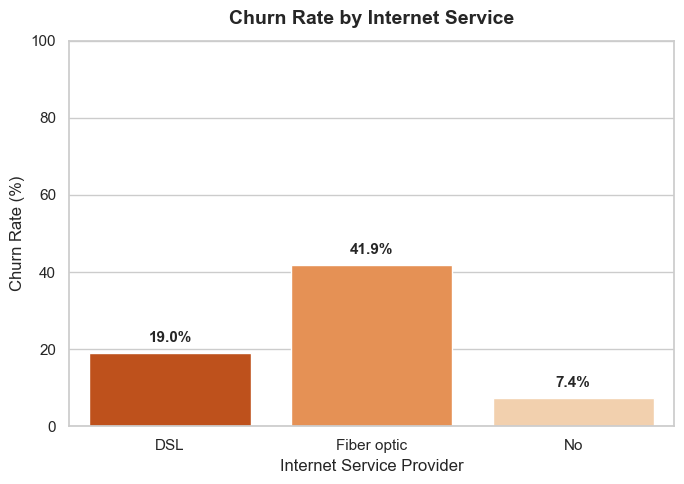

In [7]:
# Calculate and plot customer churn rate across internet service types
internet_churn = df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index()
internet_churn.columns = ['InternetService', 'ChurnRate']

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=internet_churn, x='InternetService', y='ChurnRate', hue='InternetService', palette='Oranges_r', legend=False, ax=ax)
ax.set_title('Churn Rate by Internet Service', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Internet Service Provider', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_ylim(0, 100)

for p in ax.patches:
    rate = p.get_height()
    ax.annotate(f"{rate:.1f}%",
                (p.get_x() + p.get_width() / 2., rate + 2),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.4 Churn Rate by Payment Method

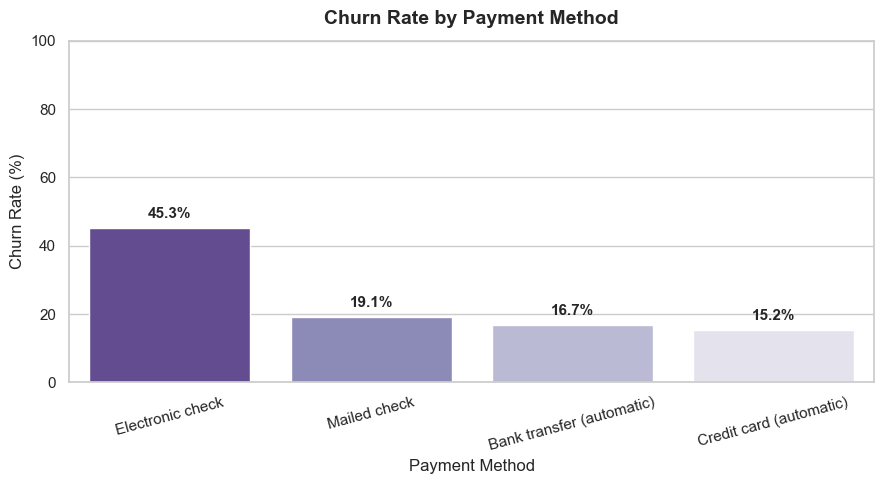

In [8]:
# Calculate and plot customer churn rate across payment methods
payment_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index()
payment_churn.columns = ['PaymentMethod', 'ChurnRate']
payment_churn = payment_churn.sort_values(by='ChurnRate', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=payment_churn, x='PaymentMethod', y='ChurnRate', hue='PaymentMethod', palette='Purples_r', legend=False, ax=ax)
ax.set_title('Churn Rate by Payment Method', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Payment Method', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=15)

for p in ax.patches:
    rate = p.get_height()
    ax.annotate(f"{rate:.1f}%",
                (p.get_x() + p.get_width() / 2., rate + 2),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.5 Customer Tenure Histogram by Churn

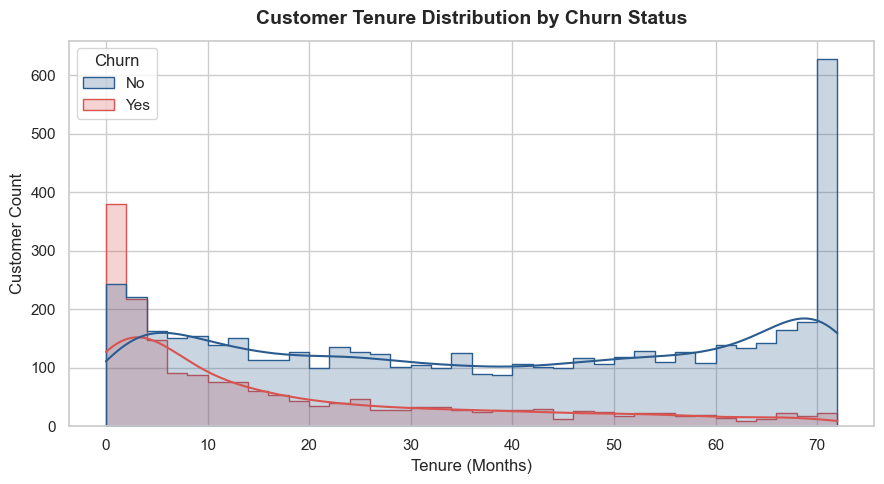

In [9]:
# Plot tenure distribution histogram stratified by churn status
fig, ax = plt.subplots(figsize=(9, 5))
palette = {'No': '#2b5c8f', 'Yes': '#d9534f'}

sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=36, palette=palette, element='step', ax=ax)
ax.set_title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Tenure (Months)', fontsize=12)
ax.set_ylabel('Customer Count', fontsize=12)

plt.tight_layout()
plt.show()

### 5.6 Monthly Charges Histogram by Churn

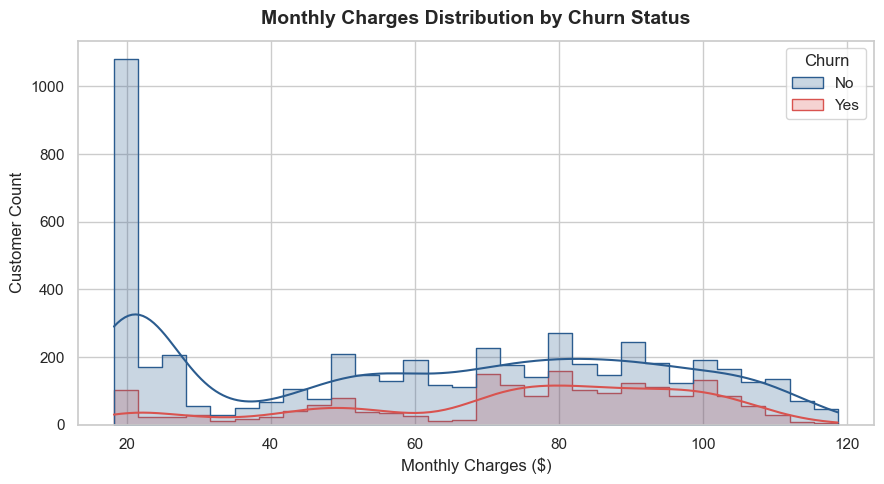

In [10]:
# Plot monthly charges distribution histogram stratified by churn status
fig, ax = plt.subplots(figsize=(9, 5))
palette = {'No': '#2b5c8f', 'Yes': '#d9534f'}

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, bins=30, palette=palette, element='step', ax=ax)
ax.set_title('Monthly Charges Distribution by Churn Status', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Monthly Charges ($)', fontsize=12)
ax.set_ylabel('Customer Count', fontsize=12)

plt.tight_layout()
plt.show()